# Models (Ludovico)

**Goal:** compare **five algorithms** seen in class, each with **two alternative preprocessing recipes**, and decide which models go on to tuning.

| | Ludovico (`preprocessing_ludovico`) | Nico (`preprocessing_nico`, `src/preprocessing.py`) |
|---|---|---|
| Numeric gaps | median | iterative imputation |
| Categorical gaps | mode | own level `(missing)` |
| Log | every numeric column (linear / distance models only) | the 3 day intervals only |
| Scaling | robust (linear / distance models only) | standard |
| Encoding | **one-hot**, levels under 50 rows grouped | **count encoding** (a level becomes its training frequency) |

**Fixed for every run:** the month feature (`features_ludovico`), the official folds (3 yearly blocks + 90-day gap), default settings. **No tuning here:** this notebook chooses the recipe per model and the shortlist for tuning.

**Not here:** hyperparameter tuning, final threshold and submission.

<div class="alert alert-block alert-info">

# TOC<a class="anchor" id="toc"></a>
* [<font color='#E8800A'>Setup</font>](#setup)
* [<font color='#E8800A'>1. The five models and the two recipes</font>](#models)
* [<font color='#E8800A'>2. Run every model with every recipe</font>](#run)
* [<font color='#E8800A'>3. Which recipe for which model</font>](#recipes)
* [<font color='#E8800A'>4. Which models go to tuning</font>](#ranking)
* [<font color='#E8800A'>5. Summary</font>](#summary)

</div>

# <font color='#E8800A'>Setup</font> <a class="anchor" id="setup"></a>
[Back to TOC](#toc)

`%run` executes `preprocessing_ludovico.ipynb` (about 2 minutes), which runs validation and cleaning first. It gives back the clean data, `official_folds`, `evaluate`, `best_threshold`, `linear_recipe` and `tree_recipe`. Nico's recipe is imported from `src/preprocessing.py`.

In [1]:
%%capture
%run ./preprocessing_ludovico.ipynb

In [2]:
import time

from sklearn.feature_selection import SelectFromModel
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from src.preprocessing import FoldPreprocessor, final_recipe

warnings.filterwarnings("ignore", category=UserWarning)        # unseen categories in a validation fold
warnings.filterwarnings("ignore", category=ConvergenceWarning)

ALWAYS_DROP = ["customer_id", "purchase_date", "random_noise"]
X_full = train.drop(columns=[TARGET])  # identifiers and date are needed to build the month, then dropped

# <font color='#E8800A'>1. The five models and the two recipes</font> <a class="anchor" id="models"></a>
[Back to TOC](#toc)

**The models.** One per family seen in class, plus the boosting already sent as V04.

| Model | Week | Family | Starting setting | Why this setting |
|---|---|---|---|---|
| Logistic regression | 6 | linear | default | |
| Gaussian naive Bayes | 7 | probabilistic | default | |
| KNN | 8 | distance | k = 25 | with k = 5 a probability can only be 0, 0.2, …, 1: too coarse for ROC AUC |
| Decision tree | 9 | tree | max depth 6 | a fully grown tree memorises the training rows |
| Gradient boosting | beyond the weeks so far | ensemble of trees | default | V04 (Kaggle 0.796); to be explained in the report |

Every setting is a **starting point**, not a choice: tuning comes after this notebook.

**The family decides the version of Ludovico's recipe:** linear, probabilistic and distance models get the *linear* version (log + robust scaler), trees get the *tree* version (no reshaping of numeric columns, trees ignore it). Nico's recipe is one for every model.

In [3]:
def add_month(df):
    """The `calendar` feature group of features_ludovico, then drop the identifiers."""
    df = df.assign(purchase_month=df["purchase_date"].dt.month.astype(str))
    return df.drop(columns=[c for c in ALWAYS_DROP if c in df.columns])


def signed_log1p(x):
    """The numeric transform of V03: equal to log1p on non-negative columns."""
    return np.sign(x) * np.log1p(np.abs(x))


MONTH_FRAME = add_month(X_full)  # the columns the recipes see


def ludovico_recipe(model, family):
    """month -> preprocessing_ludovico recipe (linear or tree version) -> model."""
    if family == "tree":
        steps = tree_recipe(model).steps
    else:
        steps = linear_recipe(model).set_params(
            prep__num__transform=FunctionTransformer(signed_log1p, feature_names_out="one-to-one")).steps
    return Pipeline([("features", FunctionTransformer(add_month)), *steps])


def nico_recipe(model, family):
    """month -> preprocessing_nico recipe (the same for every family) -> model."""
    return Pipeline([("features", FunctionTransformer(add_month)),
                     ("prep", FoldPreprocessor(final_recipe(MONTH_FRAME), selection=None)),
                     ("model", model)])


RECIPES = {"Ludovico": ludovico_recipe, "Nico": nico_recipe}

MODELS = {
    "logistic regression": (LogisticRegression(max_iter=3000), "linear"),
    "naive Bayes": (GaussianNB(), "linear"),
    "KNN (k=25)": (KNeighborsClassifier(n_neighbors=25), "linear"),
    "decision tree (depth 6)": (DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), "tree"),
    "gradient boosting": (HistGradientBoostingClassifier(random_state=RANDOM_STATE), "tree"),
}

**The reference: V03.** Logistic regression + Ludovico's recipe + month + L1 selection, the best submission so far (CV 0.802, Kaggle 0.804). It is scored on the same folds, so every model can be read against it.

In [4]:
l1_selector = SelectFromModel(
    make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, solver="saga", C=0.05, max_iter=5000)),
    importance_getter="named_steps.logisticregression.coef_",
)


def v03_pipeline():
    steps = ludovico_recipe(LogisticRegression(max_iter=2000), "linear").steps
    return Pipeline([*steps[:-1], ("select", clone(l1_selector)), steps[-1]])


V03 = "logistic regression + L1 (V03)"

**How a result is read** (as in the previous notebooks)
- **ROC AUC per fold** for comparisons: it does not depend on a threshold.
- **Paired difference:** two pipelines are compared fold by fold, so a hard year penalises both. **Better** only if the mean difference is larger than **2 SEM** of the differences.
- **Honest F1:** threshold chosen on folds 1–2, F1 scored on fold 3. It is the number comparable with Kaggle. **F1 − floor** subtracts the F1 of "always 1" on fold 3.

**Decision rules, declared before the results**
1. **Recipe per model:** Ludovico's recipe is the reference (it is the one confirmed on Kaggle). Nico's recipe replaces it for a model only if it is **better beyond 2 SEM**. A tie keeps the reference.
2. **Shortlist for tuning:** among the five models, the one with the highest mean ROC AUC, plus every model **not worse than it beyond 2 SEM**. V03 is shown as a reference, not as a competitor: it also has feature selection, which the five untuned models do not.

In [5]:
early = np.concatenate([va for _, va in official_folds[:-1]])
last = official_folds[-1][1]
FLOOR = f1_score(y.iloc[last], np.ones(len(last)))


def honest_f1(oof):
    """F1 on fold 3 at the threshold that maximises F1 on folds 1-2."""
    threshold, _ = best_threshold(y.iloc[early], oof.iloc[early])
    return f1_score(y.iloc[last], oof.iloc[last] >= threshold), threshold


def paired(a, b):
    """a minus b, fold by fold: mean difference, its SEM, ratio and folds won by a."""
    d = np.asarray(a) - np.asarray(b)
    sem = d.std(ddof=1) / np.sqrt(len(d))
    return {"diff": d.mean(), "SEM": sem, "diff / SEM": d.mean() / sem if sem > 0 else np.nan,
            "folds won": f"{int((d > 0).sum())}/{len(d)}"}

# <font color='#E8800A'>2. Run every model with every recipe</font> <a class="anchor" id="run"></a>
[Back to TOC](#toc)

5 models × 2 recipes + V03 = 11 pipelines, each refitted on the training rows of every official fold. About 2 minutes.

In [6]:
fold_auc, oofs, seconds = {}, {}, {}
runs = {(m, r): make(clone(model), family) for m, (model, family) in MODELS.items() for r, make in RECIPES.items()}
runs[V03, "Ludovico"] = v03_pipeline()

for key, pipeline in runs.items():
    start = time.time()
    scores, oofs[key] = evaluate(pipeline, official_folds, X_full, y)
    fold_auc[key] = scores["ROC AUC"].to_numpy()
    seconds[key] = time.time() - start

fold_auc = pd.DataFrame(fold_auc, index=pd.RangeIndex(1, len(official_folds) + 1, name="fold"))
fold_auc.columns.names = ["model", "recipe"]

In [7]:
board = pd.DataFrame({
    key: {"ROC AUC": fold_auc[key].mean(),
          "fold 1 / 2 / 3": " / ".join(f"{v:.3f}" for v in fold_auc[key]),
          "honest F1": honest_f1(oofs[key])[0],
          "F1 - floor": honest_f1(oofs[key])[0] - FLOOR,
          "threshold": honest_f1(oofs[key])[1],
          "seconds": seconds[key]}
    for key in fold_auc
}).T
board.index.names = ["model", "recipe"]
board.style.format({"ROC AUC": "{:.4f}", "honest F1": "{:.3f}", "F1 - floor": "{:+.3f}",
                    "threshold": "{:.2f}", "seconds": "{:.0f}"})

**Reading**

- **No untuned model beats V03** (0.796 ROC AUC, honest F1 0.802). The closest is the logistic regression without selection: 0.785 with Ludovico's recipe, 0.794 with Nico's.
- **Naive Bayes ranks reasonably (0.754 with Nico's recipe) but its F1 is below the floor** (0.701 against 0.754 for "always 1"). Its probabilities are pushed to 0 or 1, so the best threshold on folds 1–2 is 0.05–0.06 and does not transfer to fold 3. Naive Bayes assumes the columns are independent given the target; here many are near-duplicates (the invoice amounts, the count windows), so the same evidence is counted several times.
- **The decision tree is the most unstable model:** with Nico's recipe it drops to 0.659 on fold 2. A single tree changes shape with small changes in the data.
- **Gradient boosting** scores 0.774 with Ludovico's recipe, the same pipeline as V04 (CV 0.777, Kaggle 0.796).

# <font color='#E8800A'>3. Which recipe for which model</font> <a class="anchor" id="recipes"></a>
[Back to TOC](#toc)

For each model: Nico's recipe minus Ludovico's, fold by fold. Positive = Nico's recipe ranks better. Rule 1 applies.

In [8]:
recipe_table = pd.DataFrame({m: paired(fold_auc[m, "Nico"], fold_auc[m, "Ludovico"]) for m in MODELS}).T
recipe_table["verdict"] = np.where(recipe_table["diff"] > 2 * recipe_table["SEM"], "Nico better",
                                   np.where(recipe_table["diff"] < -2 * recipe_table["SEM"], "Ludovico better",
                                            "inside the noise"))
CHOSEN_RECIPE = {m: "Nico" if v == "Nico better" else "Ludovico" for m, v in recipe_table["verdict"].items()}
recipe_table["chosen"] = pd.Series(CHOSEN_RECIPE)
recipe_table.style.format({"diff": "{:+.4f}", "SEM": "{:.4f}", "diff / SEM": "{:+.1f}"})

,diff,SEM,diff / SEM,folds won,verdict,chosen
logistic regression,+0.0084,0.0081,+1.0,2/3,inside the noise,Ludovico
naive Bayes,+0.0378,0.0139,+2.7,3/3,Nico better,Nico
KNN (k=25),-0.0291,0.0123,-2.4,0/3,Ludovico better,Ludovico
decision tree (depth 6),-0.0221,0.0294,-0.8,1/3,inside the noise,Ludovico
gradient boosting,-0.0021,0.0098,-0.2,1/3,inside the noise,Ludovico


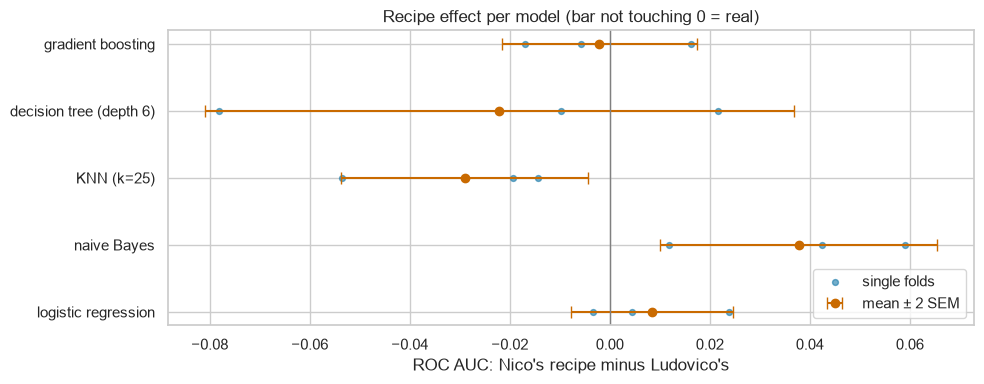

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(MODELS):
    d = fold_auc[m, "Nico"] - fold_auc[m, "Ludovico"]
    ax.scatter(d, [i] * len(d), color=PLOT_BLUE, s=18, alpha=0.6, label="single folds" if i == 0 else None)
    ax.errorbar(d.mean(), i, xerr=2 * recipe_table.loc[m, "SEM"], fmt="o", color=PLOT_ORANGE, capsize=4,
                label="mean ± 2 SEM" if i == 0 else None)
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(range(len(MODELS)), list(MODELS))
ax.set(xlabel="ROC AUC: Nico's recipe minus Ludovico's", title="Recipe effect per model (bar not touching 0 = real)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading**

- **Only two verdicts are beyond 2 SEM:**
  - **naive Bayes prefers Nico's recipe** (+0.038 ± 0.014, 3/3 folds). Count encoding gives one column per categorical instead of about 55 one-hot columns: fewer near-duplicate 0/1 columns for a model that assumes independence;
  - **KNN prefers Ludovico's recipe** (−0.029 ± 0.012, 0/3 folds), as in the head-to-head without the month: count encoding + standard scaling turns a rare level into a very large value that dominates the distances.
- **Logistic regression, decision tree and gradient boosting: inside the noise**, so rule 1 keeps Ludovico's recipe.
  - Logistic regression leans towards Nico (+0.008 ± 0.008, 2/3 folds), but its honest F1 is lower (0.776 against 0.790): the ranking gains a little, the thresholded predictions do not.
  - The decision tree is too unstable for any verdict (folds from −0.078 to +0.021).
- **The recipe matters most for the models that use distances or assume independence**, and little for trees, as expected: trees ignore scaling and logs.

# <font color='#E8800A'>4. Which models go to tuning</font> <a class="anchor" id="ranking"></a>
[Back to TOC](#toc)

Each model with the recipe chosen in §3, compared fold by fold with the best of the five. V03 is listed as the reference to beat after tuning. Rule 2 applies.

In [10]:
chosen = {m: (m, CHOSEN_RECIPE[m]) for m in MODELS}
chosen[V03] = (V03, "Ludovico")
best = max(MODELS, key=lambda m: fold_auc[chosen[m]].mean())  # among the five models, not V03

ranking = pd.DataFrame({
    m: {"recipe": key[1], "ROC AUC": fold_auc[key].mean(), "honest F1": board.loc[key, "honest F1"],
        "F1 - floor": board.loc[key, "F1 - floor"],
        **({"diff": 0.0, "SEM": np.nan, "diff / SEM": np.nan, "folds won": "best"} if m == best
           else paired(fold_auc[key], fold_auc[chosen[best]]))}
    for m, key in chosen.items()
}).T.sort_values("ROC AUC", ascending=False)
ranking["shortlist"] = [("reference" if m == V03 else m == best or row["diff"] >= -2 * row["SEM"])
                        for m, row in ranking.iterrows()]
ranking.style.format({"ROC AUC": "{:.4f}", "honest F1": "{:.3f}", "F1 - floor": "{:+.3f}",
                      "diff": "{:+.4f}", "SEM": "{:.4f}", "diff / SEM": "{:+.1f}"}, na_rep="-")

,recipe,ROC AUC,honest F1,F1 - floor,diff,SEM,diff / SEM,folds won,shortlist
logistic regression + L1 (V03),Ludovico,0.7958,0.802,+0.049,+0.0106,0.0036,+3.0,3/3,reference
logistic regression,Ludovico,0.7851,0.790,+0.037,+0.0000,-,-,best,True
KNN (k=25),Ludovico,0.7758,0.780,+0.026,-0.0093,0.0078,-1.2,1/3,True
gradient boosting,Ludovico,0.7742,0.777,+0.023,-0.0109,0.0074,-1.5,0/3,True
naive Bayes,Nico,0.7538,0.701,-0.053,-0.0314,0.0014,-21.9,0/3,False
decision tree (depth 6),Ludovico,0.7465,0.765,+0.011,-0.0387,0.0119,-3.2,0/3,False


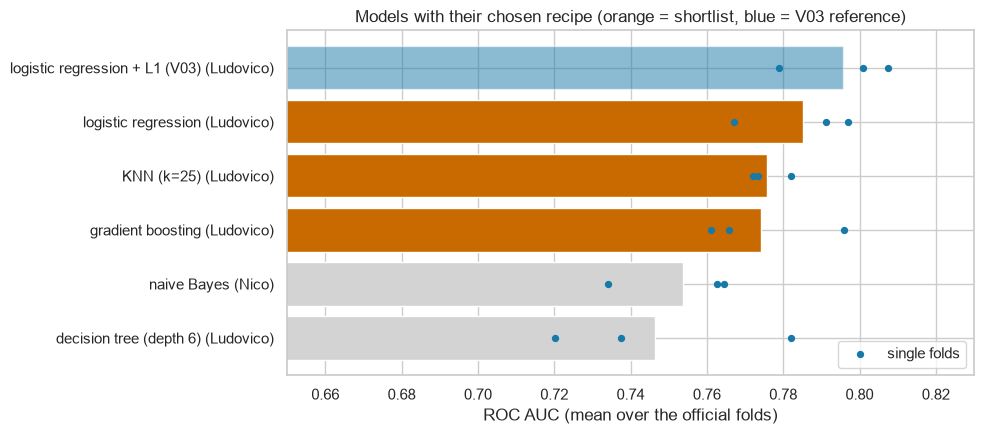

In [11]:
order = ranking.index.tolist()[::-1]
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, m in enumerate(order):
    values = fold_auc[chosen[m]]
    shortlist = ranking.loc[m, "shortlist"]
    ax.barh(i, values.mean(), color=PLOT_BLUE if shortlist == "reference" else PLOT_ORANGE if shortlist else "lightgrey",
            alpha=0.5 if shortlist == "reference" else 1)
    ax.scatter(values, [i] * len(values), color=PLOT_BLUE, s=18, zorder=3,
               label="single folds" if i == 0 else None)
ax.set_yticks(range(len(order)), [f"{m} ({chosen[m][1]})" for m in order])
ax.set_xlim(0.65, 0.83)
ax.set(xlabel="ROC AUC (mean over the official folds)", title="Models with their chosen recipe (orange = shortlist, blue = V03 reference)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Reading**

- **Shortlist for tuning: logistic regression, KNN and gradient boosting.** KNN (−0.009 ± 0.008) and gradient boosting (−0.011 ± 0.007) are below the logistic regression but not beyond 2 SEM.
- **Out: naive Bayes and the decision tree,** clearly worse (−0.031 and −0.039, worse on every fold). They stay in the report as two of the five algorithms, with the reasons above.
- **The bar to beat after tuning is V03 (0.796):** L1 selection alone adds +0.011 to the logistic regression, beyond 2 SEM (3/3 folds).
- **What tuning can still move:**
  - logistic regression: `C` of the model and of the L1 selector;
  - KNN: `k`, distance weighting; it may also profit from feature selection, since every column counts equally in a distance;
  - gradient boosting: learning rate, number of trees, depth / leaves, regularisation. Untuned it already reached 0.796 on Kaggle.

# <font color='#E8800A'>5. Summary</font> <a class="anchor" id="summary"></a>
[Back to TOC](#toc)

| Model | Best recipe (rule 1) | ROC AUC | Honest F1 | Next step |
|---|---|---|---|---|
| Logistic regression | Ludovico (tie with Nico) | 0.785 | 0.790 | **tuning** (+ L1 = V03: 0.796 / 0.802) |
| KNN (k = 25) | **Ludovico** (beyond 2 SEM) | 0.776 | 0.780 | **tuning** |
| Gradient boosting | Ludovico (tie) | 0.774 | 0.777 | **tuning** |
| Naive Bayes | **Nico** (beyond 2 SEM) | 0.754 | 0.701 | out (F1 below the floor) |
| Decision tree (depth 6) | Ludovico (tie) | 0.747 | 0.765 | out (unstable, lowest ROC AUC) |

**For the comparison with Nico's recipe:** neither recipe wins everywhere. Count encoding helps naive Bayes, one-hot helps KNN, and for the other three models the two are tied. A hybrid (count encoding for the many-level columns, one-hot for the month and the few-level columns) remains a candidate to test.

**Next:** `tuning_ludovico`, the three shortlisted models, each with its recipe, tuned on the official folds; the result to beat is V03.